# Chest X-ray Pneumonia Detection using Computer Vision (Image-only baseline + Multimodal extension) — Google Colab

| Dataset | Purpose | Where used |
|---|---|---|
| **Kermany Chest X-Ray** | Image-only baseline | Parts 1–16 (main pipeline) |
| **IU X-Ray (Indiana University)** | Image + radiology-report pairing → multimodal image + clinical text | Part B (optional, runs after the baseline) |


**Primary model:** Transfer learning with DenseNet121 (image branch) + frozen Bio_ClinicalBERT (text branch, Part B).  
**Data loading:** all datasets are read from **Google Drive** (a ZIP or an already-extracted folder) — no upload-from-device step.  
**Outputs:** trained model, test metrics, confusion matrix, ROC curve, training curves, Grad-CAM visualizations, upload-and-predict helper, and an image-only vs multimodal comparison.

> **Important research note:** The Kermany image-folder dataset provides X-ray images and class labels only, so it supports the image-only baseline. The multimodal model in Part B uses *only the pre-diagnostic text* (the study's indication) and never the findings/impression/diagnosis tags, which would leak the label.



## 0. Runtime setup



In [ ]:
# Install only the packages needed for this notebook
!pip -q install scikit-learn seaborn

## 1. Imports, reproducibility and device

In [ ]:
import os
import copy
import random
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
Device: cpu


## 2. Load the Kermany dataset from Google Drive

First put the dataset in your Drive, either as the Kaggle **ZIP** (e.g. `MyDrive/chest_xray.zip`) or as the extracted folder (e.g. `MyDrive/chest_xray/`). Then set `DRIVE_DATA` in the next cell to that path.

- A **ZIP** is extracted to the fast local Colab disk.
- A **folder** is copied to the local Colab disk (training straight from Drive is much slower). Set `COPY_TO_LOCAL = False` to read from Drive directly.

Accepted layouts (nested folders such as `chest_xray/chest_xray/` and `__MACOSX` junk are handled automatically):

```text
chest_xray/                 chest_xray/
├── train/                  ├── NORMAL/        <- "flat" layout: no train/test folders;
│   ├── NORMAL/             └── PNEUMONIA/        a stratified 70/15/15 split is created for you
│   └── PNEUMONIA/
├── val/   (optional)
└── test/
```

In [ ]:
import zipfile, shutil
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS: a .zip file OR a folder in your Google Drive
# Examples:  Path('/content/drive/MyDrive/chest_xray.zip')   Path('/content/drive/MyDrive/chest_xray')
DRIVE_DATA = Path('/content/drive/MyDrive/chest_xray')
COPY_TO_LOCAL = True          # copy a Drive *folder* to local disk for faster training

LOCAL_DIR = Path('/content/local_data')
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

def find_dataset_root(base):
    """Return (folder, layout). layout is 'split' (train/ + test/) or 'flat' (NORMAL/ + PNEUMONIA/)."""
    dirs = [base] + [p for p in base.rglob('*') if p.is_dir() and '__MACOSX' not in p.parts]
    for d in dirs:
        if {'train', 'test'} <= {c.name.lower() for c in d.iterdir() if c.is_dir()}:
            return d, 'split'
    for d in dirs:
        if {'NORMAL', 'PNEUMONIA'} <= {c.name.upper() for c in d.iterdir() if c.is_dir()}:
            return d, 'flat'
    return None, None

if not DRIVE_DATA.exists():
    raise FileNotFoundError(f"{DRIVE_DATA} not found. Check the path (Drive appears under /content/drive/MyDrive/).")

if not any(LOCAL_DIR.iterdir()):                      # skip if a previous run already prepared the data
    if DRIVE_DATA.is_file() and DRIVE_DATA.suffix.lower() == '.zip':
        print("Extracting", DRIVE_DATA.name, "to local disk...")
        with zipfile.ZipFile(DRIVE_DATA) as z:
            z.extractall(LOCAL_DIR)
        search_base = LOCAL_DIR
    elif DRIVE_DATA.is_dir() and COPY_TO_LOCAL:
        print("Copying folder from Drive to local disk (this can take a few minutes)...")
        shutil.copytree(DRIVE_DATA, LOCAL_DIR / DRIVE_DATA.name, dirs_exist_ok=True)
        search_base = LOCAL_DIR
    elif DRIVE_DATA.is_dir():
        search_base = DRIVE_DATA
    else:
        raise ValueError("DRIVE_DATA must be a .zip file or a folder.")
else:
    print("Using data already prepared in", LOCAL_DIR)
    search_base = LOCAL_DIR

DATA_ROOT, LAYOUT = find_dataset_root(search_base)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find train/ + test/ folders or NORMAL/ + PNEUMONIA/ folders in the dataset. "
        "Check the ZIP/folder contents."
    )

print("Dataset root:", DATA_ROOT, "| layout:", LAYOUT)
print("Top-level entries:", sorted(p.name for p in DATA_ROOT.iterdir()))

Mounted at /content/drive
Copying folder from Drive to local disk (this can take a few minutes)...
Dataset root: /content/local_data/chest_xray | layout: split
Top-level entries: ['chest_xray', 'test', 'train', 'val']


## 3. Discover images and verify class labels

This cell supports the common Kermany folder names `NORMAL` and `PNEUMONIA` (case-insensitive). It checks that image files exist and builds a manifest. For the `split` layout the official `test/` directory is kept untouched for final evaluation; for the `flat` layout a stratified 70/15/15 train/val/test split is created.

In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
CLASS_TO_LABEL = {'NORMAL': 0, 'PNEUMONIA': 1}
SPLIT_ALIASES = {'train': 'train', 'val': 'val', 'valid': 'val', 'validation': 'val', 'test': 'test'}

def collect_dir(folder, split_name):
    rows = []
    for class_dir in folder.iterdir():
        cname = class_dir.name.upper()
        if class_dir.is_dir() and cname in CLASS_TO_LABEL:
            for p in class_dir.rglob('*'):
                if p.is_file() and not p.name.startswith('.') and p.suffix.lower() in IMAGE_EXTS:
                    rows.append({'image_path': str(p), 'split': split_name,
                                 'class_name': cname, 'label': CLASS_TO_LABEL[cname]})
    return rows

all_rows = []
if LAYOUT == 'split':
    for d in DATA_ROOT.iterdir():
        if d.is_dir() and d.name.lower() in SPLIT_ALIASES:
            all_rows.extend(collect_dir(d, SPLIT_ALIASES[d.name.lower()]))
else:  # flat layout -> create a stratified split
    all_rows = collect_dir(DATA_ROOT, 'all')

manifest = pd.DataFrame(all_rows)
if manifest.empty:
    raise FileNotFoundError(f"No images found under {DATA_ROOT}.")

if LAYOUT == 'flat':
    idx_trainval, idx_test = train_test_split(manifest.index, test_size=0.15, random_state=SEED,
                                              stratify=manifest['label'])
    idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15 / 0.85, random_state=SEED,
                                          stratify=manifest.loc[idx_trainval, 'label'])
    manifest.loc[idx_train, 'split'] = 'train'
    manifest.loc[idx_val, 'split'] = 'val'
    manifest.loc[idx_test, 'split'] = 'test'

print("Total images:", len(manifest))
display(pd.crosstab(manifest['split'], manifest['class_name'], margins=True))
print("\nClass mapping:", CLASS_TO_LABEL)
print("\nExample paths:")
display(manifest.head())

Total images: 5856


class_name,NORMAL,PNEUMONIA,All
split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856



Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}

Example paths:


,image_path,split,class_name,label
0,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
1,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
2,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
3,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1
4,/content/local_data/chest_xray/train/PNEUMONIA...,train,PNEUMONIA,1


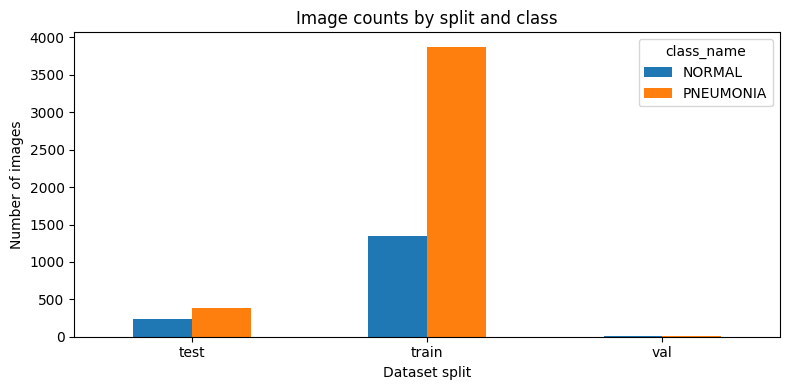

Unreadable files in sample: 0


In [ ]:
# Visualize split/class counts
count_table = pd.crosstab(manifest['split'], manifest['class_name'])
ax = count_table.plot(kind='bar', figsize=(8, 4))
ax.set_title('Image counts by split and class')
ax.set_xlabel('Dataset split')
ax.set_ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Verify a sample of images can be opened
bad_files = []
for p in manifest['image_path'].sample(min(100, len(manifest)), random_state=SEED):
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad_files.append(p)

print("Unreadable files in sample:", len(bad_files))
if bad_files:
    print(*bad_files[:10], sep='\n')

## 4. Create train, validation and test sets

- If the supplied `val/` split has at least 100 images and both classes (or you used the flat layout, where val/ was created for you), it is used as validation.
- If `val/` is missing or unusually tiny (as in some Kermany copies), a stratified validation split is drawn from `train/`.
- The supplied `test/` split is never used for training or model selection.
- This dataset does not provide reliable patient IDs in the folder structure. The split is therefore image-level, not guaranteed patient-level. State this limitation in any report.

In [ ]:
train_all = manifest[manifest.split == 'train'].copy()
test_df = manifest[manifest.split == 'test'].copy()
val_existing = manifest[manifest.split == 'val'].copy()

if train_all.empty or test_df.empty:
    raise ValueError("Both train/ and test/ folders must contain images from NORMAL and PNEUMONIA.")

if set(train_all.label.unique()) != {0, 1} or set(test_df.label.unique()) != {0, 1}:
    raise ValueError("Train and test must each contain both NORMAL and PNEUMONIA classes.")

if (LAYOUT == 'flat' or len(val_existing) >= 100) and set(val_existing.label.unique()) == {0, 1}:
    train_df = train_all.copy()
    val_df = val_existing.copy()
    validation_source = "provided val/ folder"
else:
    train_df, val_df = train_test_split(
        train_all,
        test_size=0.15,
        random_state=SEED,
        stratify=train_all['label']
    )
    validation_source = "15% stratified split from train/ (provided val/ was absent or too small)"

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Validation source:", validation_source)
for name, frame in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f"{name}: {len(frame)} images | counts: {frame.label.value_counts().sort_index().to_dict()}")

Validation source: 15% stratified split from train/ (provided val/ was absent or too small)
Train: 4433 images | counts: {0: 1140, 1: 3293}
Validation: 783 images | counts: {0: 201, 1: 582}
Test: 624 images | counts: {0: 234, 1: 390}


## 5. Image preprocessing and DataLoaders

Images are resized to 224×224 and normalized using ImageNet statistics because DenseNet121 is initialized with ImageNet pretrained weights. Mild augmentation is applied to training images only.

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 8
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class ChestXrayDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(row.image_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(float(row.label), dtype=torch.float32)
        return image, label, row.image_path

train_ds = ChestXrayDataset(train_df, train_transform)
val_ds = ChestXrayDataset(val_df, eval_transform)
test_ds = ChestXrayDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))

print("Loaders ready.")
print("Batches — train:", len(train_loader), "validation:", len(val_loader), "test:", len(test_loader))

Loaders ready.
Batches — train: 555 validation: 98 test: 78


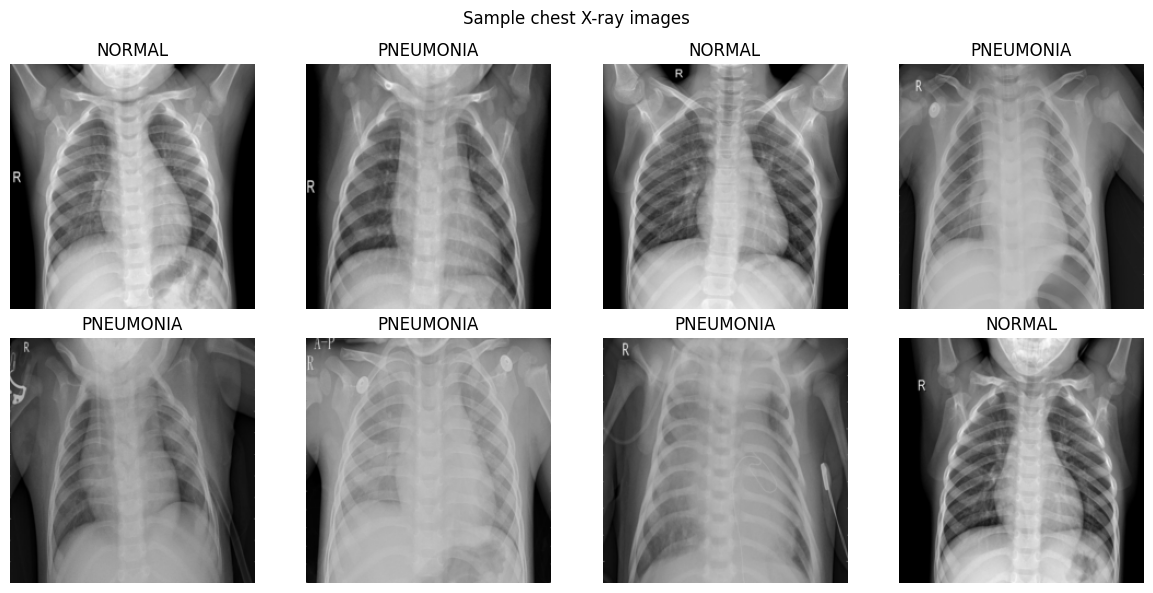

In [ ]:
# Display a few training images before normalization is applied
preview_ds = ChestXrayDataset(train_df, transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
]))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.flat, np.random.choice(len(preview_ds), min(8, len(preview_ds)), replace=False)):
    image, label, path = preview_ds[idx]
    ax.imshow(image.permute(1, 2, 0).numpy(), cmap='gray')
    ax.set_title("PNEUMONIA" if int(label.item()) == 1 else "NORMAL")
    ax.axis('off')
plt.suptitle("Sample chest X-ray images")
plt.tight_layout()
plt.show()

## 6. Build DenseNet121

We use transfer learning with ImageNet pretrained DenseNet121. The classifier head is replaced with a single logit for binary classification. The final dense block and classifier are trainable; earlier feature layers are initially frozen to reduce training time and overfitting.

In [ ]:
from torchvision.models import DenseNet121_Weights

weights = DenseNet121_Weights.DEFAULT
model = models.densenet121(weights=weights)

# Freeze the feature extractor first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the final dense block and final normalization
for name, param in model.features.named_parameters():
    if name.startswith('denseblock4') or name.startswith('norm5'):
        param.requires_grad = True

in_features = model.classifier.in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.35),
    nn.Linear(in_features, 1)
)
model = model.to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 152MB/s]


Trainable parameters: 2,161,153 / 6,954,881


## 7. Loss, optimizer and training functions

The positive-class weight is computed from the training split to account for class imbalance. We select the best checkpoint using validation AUROC (with validation loss as a fallback if AUROC cannot be calculated).

In [ ]:
train_counts = train_df.label.value_counts().to_dict()
neg_count = train_counts.get(0, 0)
pos_count = train_counts.get(1, 0)
pos_weight = torch.tensor([neg_count / max(pos_count, 1)], dtype=torch.float32, device=DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2
)

def run_one_epoch(model, loader, training=False):
    model.train(training)
    running_loss = 0.0
    all_labels, all_probs = [], []

    for images, labels, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        probs = torch.sigmoid(logits)
        running_loss += loss.item() * images.size(0)
        all_labels.extend(labels.detach().cpu().numpy().astype(int).tolist())
        all_probs.extend(probs.detach().cpu().numpy().tolist())

    avg_loss = running_loss / max(1, len(loader.dataset))
    y_true = np.asarray(all_labels)
    y_prob = np.asarray(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    metrics = {
        'loss': avg_loss,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'auroc': auc
    }
    return metrics, y_true, y_prob

print("Training functions ready.")

Training functions ready.


## 8. Train the model

Start with up to 5 epochs. Early stopping will stop training if validation AUROC does not improve for 4 epochs. On a T4 GPU, runtime depends on dataset size and Colab availability. If the session disconnects, rerun setup and load the saved checkpoint if available.

In [ ]:
EPOCHS = 5
PATIENCE = 3
best_auc = -np.inf
best_val_loss = np.inf
epochs_without_improvement = 0
history = []

OUTPUT_DIR = Path('/content/pneumonia_project_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = OUTPUT_DIR / 'best_densenet121_pneumonia.pth'

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_metrics, _, _ = run_one_epoch(model, train_loader, training=True)
    val_metrics, _, _ = run_one_epoch(model, val_loader, training=False)

    current_auc = val_metrics['auroc']
    score = current_auc if not np.isnan(current_auc) else -val_metrics['loss']
    scheduler.step(score)

    row = {'epoch': epoch}
    row.update({f'train_{k}': v for k, v in train_metrics.items()})
    row.update({f'val_{k}': v for k, v in val_metrics.items()})
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val AUROC {val_metrics['auroc']:.4f} | "
        f"val F1 {val_metrics['f1']:.4f}"
    )

    improved = (current_auc > best_auc) if not np.isnan(current_auc) else (val_metrics['loss'] < best_val_loss)
    if improved:
        best_auc = current_auc if not np.isnan(current_auc) else best_auc
        best_val_loss = min(best_val_loss, val_metrics['loss'])
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        epochs_without_improvement = 0
        print("  Saved new best checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print(f"Training time: {(time.time() - start_time)/60:.1f} minutes")
print("Best checkpoint:", BEST_MODEL_PATH)

history_df = pd.DataFrame(history)
display(history_df.round(4))
history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))

Epoch 01/5 | train loss 0.0577 | val loss 0.0484 | val AUROC 0.9949 | val F1 0.9748
  Saved new best checkpoint.
Epoch 02/5 | train loss 0.0465 | val loss 0.0403 | val AUROC 0.9966 | val F1 0.9728
  Saved new best checkpoint.
Epoch 03/5 | train loss 0.0439 | val loss 0.0949 | val AUROC 0.9963 | val F1 0.9805
Epoch 04/5 | train loss 0.0318 | val loss 0.0374 | val AUROC 0.9974 | val F1 0.9801
  Saved new best checkpoint.
Epoch 05/5 | train loss 0.0299 | val loss 0.0856 | val AUROC 0.9970 | val F1 0.9815
Training time: 97.0 minutes
Best checkpoint: /content/pneumonia_project_outputs/best_densenet121_pneumonia.pth


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,train_auroc,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_auroc
0,1,0.0577,0.9648,0.9834,0.9690,0.9761,0.9922,0.0484,0.9630,0.9842,0.9656,0.9748,0.9949
1,2,0.0465,0.9677,0.9858,0.9705,0.9781,0.9949,0.0403,0.9604,0.9928,0.9536,0.9728,0.9966
2,3,0.0439,0.9756,0.9866,0.9806,0.9836,0.9957,0.0949,0.9706,0.9697,0.9914,0.9805,0.9963
3,4,0.0318,0.9801,0.9926,0.9806,0.9866,0.9974,0.0374,0.9706,0.9895,0.9708,0.9801,0.9974
4,5,0.0299,0.9835,0.9921,0.9857,0.9889,0.9980,0.0856,0.9719,0.9636,1.0000,0.9815,0.9970


<All keys matched successfully>

## 9. Plot training curves

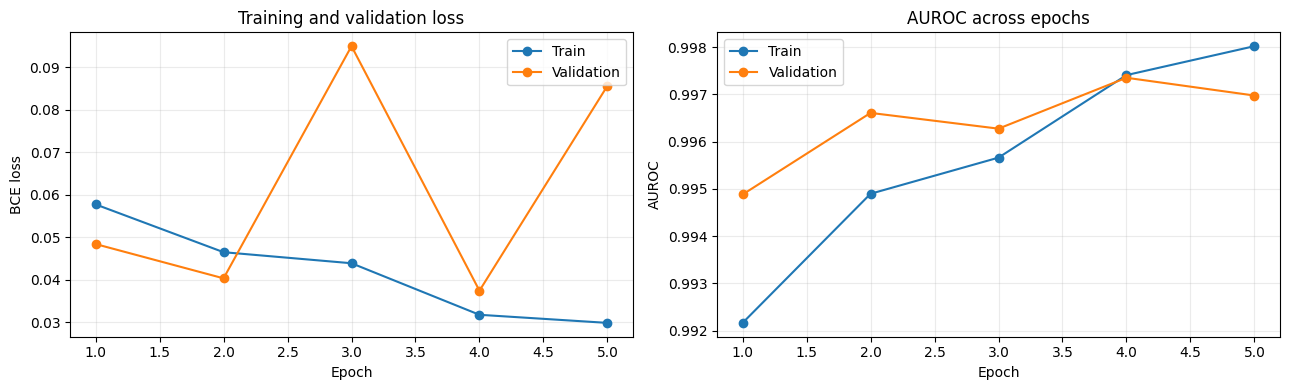

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df.epoch, history_df.train_loss, marker='o', label='Train')
axes[0].plot(history_df.epoch, history_df.val_loss, marker='o', label='Validation')
axes[0].set_title('Training and validation loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE loss')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_df.epoch, history_df.train_auroc, marker='o', label='Train')
axes[1].plot(history_df.epoch, history_df.val_auroc, marker='o', label='Validation')
axes[1].set_title('AUROC across epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUROC')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. Final evaluation on the held-out test set

The test set is evaluated only after model selection is complete. The threshold below is 0.5 for a straightforward baseline; threshold tuning, if needed, must be done using validation data only.

In [ ]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    ys, probs, paths = [], [], []
    for images, labels, batch_paths in loader:
        images = images.to(DEVICE)
        logits = model(images).squeeze(1)
        batch_probs = torch.sigmoid(logits).cpu().numpy()
        probs.extend(batch_probs.tolist())
        ys.extend(labels.numpy().astype(int).tolist())
        paths.extend(list(batch_paths))
    return np.asarray(ys), np.asarray(probs), paths

y_test, p_test, test_paths = predict_loader(model, test_loader)
y_pred = (p_test >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

test_results = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'sensitivity_recall': recall_score(y_test, y_pred, zero_division=0),
    'specificity': tn / max(tn + fp, 1),
    'f1_score': f1_score(y_test, y_pred, zero_division=0),
    'auroc': roc_auc_score(y_test, p_test) if len(np.unique(y_test)) == 2 else np.nan,
    'auprc': average_precision_score(y_test, p_test) if len(np.unique(y_test)) == 2 else np.nan
}

results_df = pd.DataFrame([test_results]).T.rename(columns={0: 'Test result'})
display(results_df.round(4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['NORMAL', 'PNEUMONIA'], zero_division=0))

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

results_df.to_csv(OUTPUT_DIR / 'test_metrics.csv')
with open(OUTPUT_DIR / 'test_metrics.json', 'w') as f:
    json.dump({k: (None if np.isnan(v) else float(v)) for k, v in test_results.items()}, f, indent=2)

,Test result
accuracy,0.8846
precision,0.8457
sensitivity_recall,0.9974
specificity,0.6966
f1_score,0.9153
auroc,0.9515
auprc,0.9619



Classification report:
              precision    recall  f1-score   support

      NORMAL       0.99      0.70      0.82       234
   PNEUMONIA       0.85      1.00      0.92       390

    accuracy                           0.88       624
   macro avg       0.92      0.85      0.87       624
weighted avg       0.90      0.88      0.88       624

Confusion matrix [[TN, FP], [FN, TP]]:
[[163  71]
 [  1 389]]


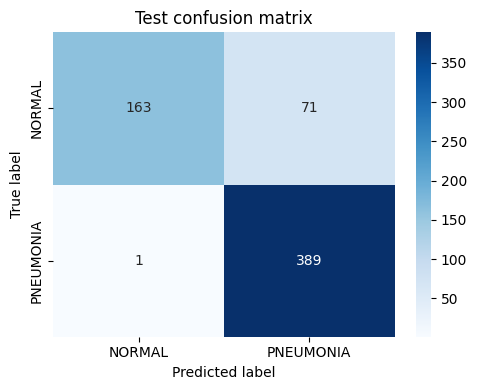

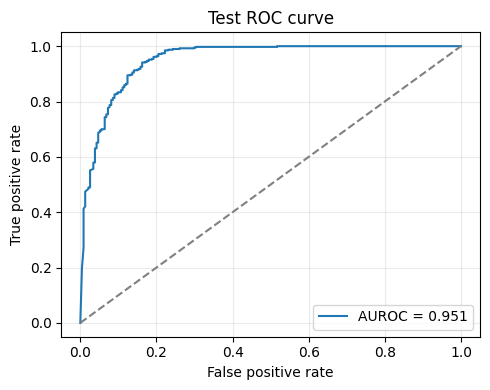

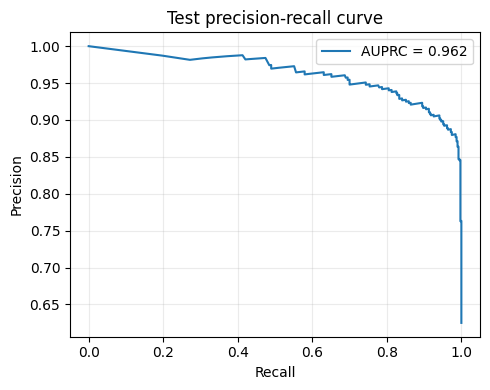

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Test confusion matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

fpr, tpr, _ = roc_curve(y_test, p_test)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUROC = {test_results['auroc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Test ROC curve')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curve.png', dpi=160, bbox_inches='tight')
plt.show()

precision, recall, _ = precision_recall_curve(y_test, p_test)
plt.figure(figsize=(5, 4))
plt.plot(recall, precision, label=f"AUPRC = {test_results['auprc']:.3f}")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Test precision-recall curve')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'precision_recall_curve.png', dpi=160, bbox_inches='tight')
plt.show()

## 11. Save test-set predictions

In [ ]:
predictions_df = pd.DataFrame({
    'image_path': test_paths,
    'true_label': y_test,
    'true_class': ['PNEUMONIA' if x == 1 else 'NORMAL' for x in y_test],
    'p_pneumonia': p_test,
    'predicted_label': y_pred,
    'predicted_class': ['PNEUMONIA' if x == 1 else 'NORMAL' for x in y_pred],
    'correct': (y_test == y_pred)
})
display(predictions_df.head(10))
predictions_df.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

,image_path,true_label,true_class,p_pneumonia,predicted_label,predicted_class,correct
0,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.998988,1,PNEUMONIA,True
1,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.941108,1,PNEUMONIA,True
2,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.999302,1,PNEUMONIA,True
3,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
4,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
5,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
6,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.999999,1,PNEUMONIA,True
7,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
8,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,1.000000,1,PNEUMONIA,True
9,/content/local_data/chest_xray/test/PNEUMONIA/...,1,PNEUMONIA,0.996808,1,PNEUMONIA,True


## 12. Grad-CAM explainability

Grad-CAM highlights image regions that contribute to the selected model score. It is a visualization aid, not proof that the model is reasoning clinically correctly. DenseNet may use shortcuts or acquisition artifacts, so inspect examples critically.

/tmp/ipykernel_492/1880338647.py:20: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  score.backward()


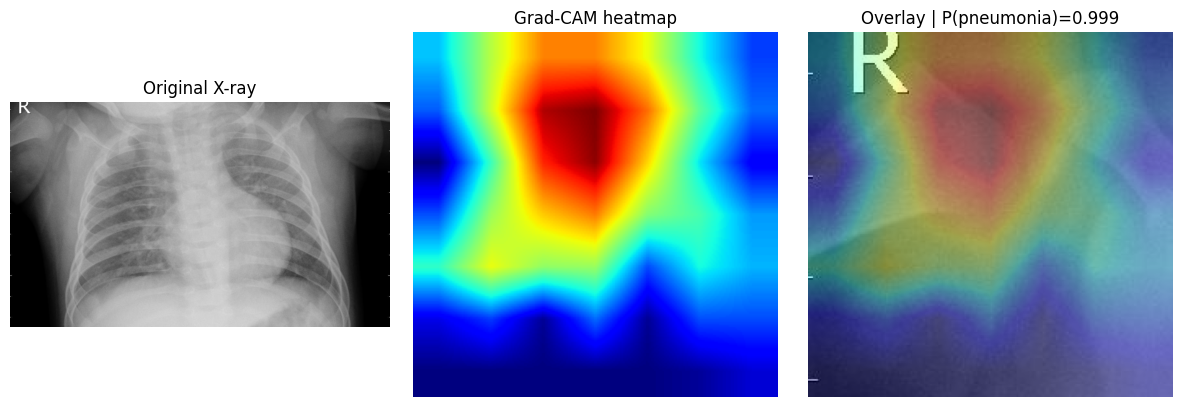

In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.fwd_handle = target_layer.register_forward_hook(self._save_activation)
        self.bwd_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logit = self.model(input_tensor).squeeze()
        score = logit if logit.item() >= 0 else -logit
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(
            cam, size=input_tensor.shape[-2:], mode='bilinear', align_corners=False
        )
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, float(torch.sigmoid(logit).detach().cpu())

    def close(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

# DenseNet final convolutional feature block
target_layer = model.features.denseblock4
gradcam = GradCAM(model, target_layer)

# Choose one correctly or incorrectly classified test image by index
sample_index = 0
sample_path = test_paths[sample_index]
raw_image = Image.open(sample_path).convert('RGB')
input_tensor = eval_transform(raw_image).unsqueeze(0).to(DEVICE)

heatmap, probability = gradcam.generate(input_tensor)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(raw_image, cmap='gray')
plt.title('Original X-ray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title('Grad-CAM heatmap')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(raw_image)
plt.imshow(heatmap, cmap='jet', alpha=0.35)
plt.title(f'Overlay | P(pneumonia)={probability:.3f}')
plt.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gradcam_example.png', dpi=160, bbox_inches='tight')
plt.show()
gradcam.close()

## 13. Reusable single-image prediction function (dataset image or an image in your Drive)

Use `predict_xray(path)` for any image file, or `predict_from_drive(path)` for a single image or a whole folder of images in your Drive. Predictions are model outputs, not medical diagnoses.

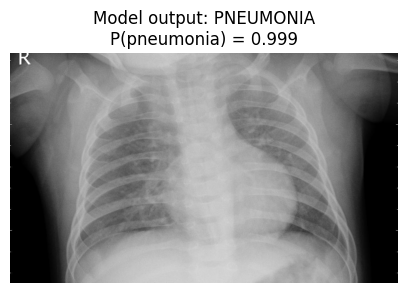

{'predicted_class': 'PNEUMONIA', 'p_pneumonia': 0.9989877343177795}

In [ ]:
@torch.no_grad()
def predict_xray(image_path, threshold=0.5):
    model.eval()
    image = Image.open(image_path).convert('RGB')
    x = eval_transform(image).unsqueeze(0).to(DEVICE)
    probability = torch.sigmoid(model(x).squeeze()).item()
    predicted = 'PNEUMONIA' if probability >= threshold else 'NORMAL'

    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap='gray')
    plt.title(f"Model output: {predicted}\nP(pneumonia) = {probability:.3f}")
    plt.axis('off')
    plt.show()

    return {'predicted_class': predicted, 'p_pneumonia': probability}

# Example:
predict_xray(test_paths[0])

In [ ]:
def predict_from_drive(path, threshold=0.5):
    """Run the trained model on one image, or on every image in a Drive folder."""
    path = Path(path)
    imgs = [path] if path.is_file() else sorted(p for p in path.rglob('*')
                                               if p.is_file() and not p.name.startswith('.')
                                               and p.suffix.lower() in IMAGE_EXTS)
    if not imgs:
        raise FileNotFoundError(f"No images found at {path}")
    results = {}
    for p in imgs[:20]:                       # cap plots at 20 images per call
        try:
            results[p.name] = predict_xray(p, threshold=threshold)
        except Exception as e:
            print(f"Could not read {p.name}: {e}")
    return results

# Example (edit the path):
# predict_from_drive('/content/drive/MyDrive/my_xrays/example.jpeg')

## 14. Export model and project outputs

This cell saves the trained weights, class mapping, metrics, history, plots and predictions into one ZIP file. You can download it from the Colab file browser or use the download helper below.

In [ ]:
# Save model state and metadata
torch.save({
    'model_state_dict': model.state_dict(),
    'architecture': 'DenseNet121',
    'class_to_label': CLASS_TO_LABEL,
    'image_size': IMG_SIZE,
    'threshold': 0.5
}, OUTPUT_DIR / 'densenet121_pneumonia_checkpoint.pth')

with open(OUTPUT_DIR / 'project_metadata.json', 'w') as f:
    json.dump({
        'project': 'Chest X-ray Pneumonia Detection',
        'dataset': 'Kermany/Kaggle Chest X-Ray',
        'architecture': 'DenseNet121 transfer learning',
        'classes': CLASS_TO_LABEL,
        'image_size': IMG_SIZE,
        'validation_source': validation_source,
        'test_metrics': {k: (None if np.isnan(v) else float(v)) for k, v in test_results.items()},
        'limitations': [
            'Educational/research prototype, not for clinical diagnosis.',
            'Kermany folder dataset does not include paired pre-diagnostic clinical text.',
            'Patient-level separation cannot be guaranteed from folder labels alone.'
        ]
    }, f, indent=2)

import shutil
zip_path = shutil.make_archive('/content/pneumonia_project_outputs', 'zip', OUTPUT_DIR)
print("Created:", zip_path)

from google.colab import files
files.download(zip_path)

Created: /content/pneumonia_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Optional: copy results to Google Drive

Drive is already mounted from Section 2. Run this cell to keep the outputs in Drive after the session ends; otherwise just download the ZIP from the previous cell.

In [ ]:
DRIVE_OUTPUT = Path('/content/drive/MyDrive/pneumonia_project_outputs')
DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)

for item in OUTPUT_DIR.iterdir():
    if item.is_file():
        shutil.copy2(item, DRIVE_OUTPUT / item.name)

print("Outputs copied to:", DRIVE_OUTPUT)
print("Files:", sorted(p.name for p in DRIVE_OUTPUT.iterdir()))

Outputs copied to: /content/drive/MyDrive/pneumonia_project_outputs
Files: ['best_densenet121_pneumonia.pth', 'confusion_matrix.png', 'densenet121_pneumonia_checkpoint.pth', 'gradcam_example.png', 'precision_recall_curve.png', 'project_metadata.json', 'roc_curve.png', 'test_metrics.csv', 'test_metrics.json', 'test_predictions.csv', 'training_curves.png', 'training_history.csv']


# Part B — Multimodal extension: image + clinical text (IU X-Ray)

**What it does:** fuses DenseNet121 image features with a frozen **Bio_ClinicalBERT** embedding of the study's *indication* text (the pre-diagnostic reason for the exam), then compares it against an image-only model on the **same** split.

**Leakage guard (important):** IU X-Ray reports also contain *findings*, *impression*, *Problems* and *MeSH* fields. These describe the diagnosis, so they are used **only to create the label** and are never fed to the text encoder. Using them as input would make the task trivial and the results meaningless.

**Dataset format (IU X-Ray, e.g. the Kaggle "Chest X-rays (Indiana University)" copy)** — put these in one Google Drive folder (set `MM_DRIVE_DIR` below):
1. `indiana_reports.csv` (columns incl. `uid`, `indication`, `findings`, `impression`, `Problems`, `MeSH`)
2. `indiana_projections.csv` (columns `uid`, `filename`, `projection`)
3. the images, either as a **ZIP** (e.g. `images_normalized.zip`) or as an extracted image folder



In [1]:
!pip -q install transformers

In [2]:
import os, shutil
from pathlib import Path

# remove the bad HTML "archives"
shutil.rmtree("/content/iu_xray", ignore_errors=True)

!pip -q install kagglehub
import kagglehub
path = Path(kagglehub.dataset_download("raddar/chest-xrays-indiana-university"))
print(path)
for p in sorted(path.rglob("*"))[:20]:
    print(p)

Using Colab cache for faster access to the 'chest-xrays-indiana-university' dataset.
/kaggle/input/chest-xrays-indiana-university
/kaggle/input/chest-xrays-indiana-university/images
/kaggle/input/chest-xrays-indiana-university/images/images_normalized
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1000_IM-0003-1001.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1000_IM-0003-2001.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1000_IM-0003-3001.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1001_IM-0004-1001.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1001_IM-0004-1002.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1002_IM-0004-1001.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1002_IM-0004-2001.dcm.png
/kaggle/input/chest-xrays-indiana-university/images/images_normalized/1003_I

In [3]:
from pathlib import Path

xml_files = list(Path("iu_xray/reports").rglob("*.xml"))
png_files = list(Path("iu_xray/images").rglob("*.png"))

print("XML reports:", len(xml_files))
print("PNG images:", len(png_files))

print("Sample XML:", xml_files[:3])
print("Sample PNG:", png_files[:3])

XML reports: 0
PNG images: 0
Sample XML: []
Sample PNG: []


In [4]:
import pandas as pd, numpy as np, re
from pathlib import Path
import kagglehub

root = Path(kagglehub.dataset_download("raddar/chest-xrays-indiana-university"))
reports = pd.read_csv(next(root.rglob("indiana_reports.csv")))
proj    = pd.read_csv(next(root.rglob("indiana_projections.csv")))
print(reports.columns.tolist(), proj.columns.tolist())

img_dir = next(root.rglob("images_normalized"), None) or next(root.rglob("*.png")).parent
df = proj.merge(reports, on="uid")
df = df[df["projection"] == "Frontal"].copy()          # frontal views only
df["path"] = df["filename"].apply(lambda f: str(img_dir / f))
df = df[df["path"].apply(lambda p: Path(p).exists())]

def clean(t):
    t = "" if pd.isna(t) else str(t)
    t = re.sub(r"X{2,}", "", t)                        # de-identification tokens
    return re.sub(r"\s+", " ", t).strip()

df["history"] = df["indication"].apply(clean)           # patient history only (see note)
df["abnormal"] = (df["MeSH"].fillna("normal").str.strip().str.lower() != "normal").astype(int)
df["pneumonia"] = df[["MeSH", "Problems"]].fillna("").agg(" ".join, axis=1) \
                    .str.contains("pneumonia", case=False).astype(int)

print(len(df), "images |", df["uid"].nunique(), "patients")
print(df[["abnormal", "pneumonia"]].sum())
df.head(3)

Using Colab cache for faster access to the 'chest-xrays-indiana-university' dataset.
['uid', 'MeSH', 'Problems', 'image', 'indication', 'comparison', 'findings', 'impression'] ['uid', 'filename', 'projection']
3818 images | 3689 patients
abnormal     2431
pneumonia      39
dtype: int64


,uid,filename,projection,MeSH,Problems,image,indication,comparison,findings,impression,path,history,abnormal,pneumonia
0,1,1_IM-0001-4001.dcm.png,Frontal,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.,/kaggle/input/chest-xrays-indiana-university/i...,Positive TB test,0,0
2,2,2_IM-0652-1001.dcm.png,Frontal,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.,/kaggle/input/chest-xrays-indiana-university/i...,Preop bariatric surgery.,1,0
4,3,3_IM-1384-1001.dcm.png,Frontal,normal,normal,Xray Chest PA and Lateral,"rib pain after a XXXX, XXXX XXXX steps this XX...",NaN,NaN,"No displaced rib fractures, pneumothorax, or p...",/kaggle/input/chest-xrays-indiana-university/i...,"rib pain after a , steps this . Pain to R back...",0,0


In [5]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from transformers import AutoTokenizer, AutoModel
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit

LABEL = "abnormal"          # or "pneumonia" if you have enough positives
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(df, groups=df["uid"]))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=42)
tr_sub, va_sub = next(gss2.split(df.iloc[tr_idx], groups=df.iloc[tr_idx]["uid"]))
train_df, val_df, test_df = df.iloc[tr_idx].iloc[tr_sub], df.iloc[tr_idx].iloc[va_sub], df.iloc[te_idx]

tok = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = T.Compose([T.Resize((224, 224)), T.RandomRotation(5), T.ToTensor(), norm])
tf_eval  = T.Compose([T.Resize((224, 224)), T.ToTensor(), norm])

class CXRDataset(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        img = self.tf(Image.open(r["path"]).convert("RGB"))
        t = tok(r["history"] or "no history", padding="max_length", truncation=True,
                max_length=48, return_tensors="pt")
        return img, t["input_ids"][0], t["attention_mask"][0], torch.tensor(r[LABEL], dtype=torch.float32)

mk = lambda d, tf, sh: DataLoader(CXRDataset(d, tf), batch_size=32, shuffle=sh, num_workers=2)
train_dl, val_dl, test_dl = mk(train_df, tf_train, True), mk(val_df, tf_eval, False), mk(test_df, tf_eval, False)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

In [6]:
class ImageOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = models.resnet18(weights="IMAGENET1K_V1")
        self.cnn.fc = nn.Linear(512, 1)
    def forward(self, img, ids, mask): return self.cnn(img).squeeze(1)

class Multimodal(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = models.resnet18(weights="IMAGENET1K_V1"); self.cnn.fc = nn.Identity()
        self.bert = AutoModel.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
        self.head = nn.Sequential(nn.Linear(512 + 768, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(self, img, ids, mask):
        v = self.cnn(img)
        t = self.bert(input_ids=ids, attention_mask=mask).last_hidden_state[:, 0]  # [CLS]
        return self.head(torch.cat([v, t], dim=1)).squeeze(1)

In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
dev = "cuda" if torch.cuda.is_available() else "cpu"

def run_eval(model, dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for img, ids, m, y in dl:
            ps += torch.sigmoid(model(img.to(dev), ids.to(dev), m.to(dev))).cpu().tolist(); ys += y.tolist()
    return np.array(ys), np.array(ps)

def fit(model, epochs=5, lr=1e-4):
    model.to(dev)
    pos = train_df[LABEL].mean()
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - pos) / pos, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state = 0, None
    for ep in range(epochs):
        model.train()
        for img, ids, m, y in train_dl:
            opt.zero_grad()
            loss = loss_fn(model(img.to(dev), ids.to(dev), m.to(dev)), y.to(dev))
            loss.backward(); opt.step()
        y, p = run_eval(model, val_dl); auc = roc_auc_score(y, p)
        print(f"epoch {ep+1} | loss {loss.item():.3f} | val AUROC {auc:.3f}")
        if auc > best: best, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); return model

for name, M in [("image-only", ImageOnly), ("multimodal", Multimodal)]:
    print(f"\n=== {name} ===")
    model = fit(M())
    y, p = run_eval(model, test_dl)
    print(f"TEST AUROC {roc_auc_score(y, p):.3f} | AUPRC {average_precision_score(y, p):.3f}")
    print(classification_report(y, p > 0.5, digits=3))


=== image-only ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


epoch 1 | loss 0.349 | val AUROC 0.740
epoch 2 | loss 0.370 | val AUROC 0.739
epoch 3 | loss 0.409 | val AUROC 0.714
epoch 4 | loss 0.435 | val AUROC 0.740
epoch 5 | loss 0.350 | val AUROC 0.750
TEST AUROC 0.792 | AUPRC 0.881
              precision    recall  f1-score   support

         0.0      0.596     0.663     0.628       267
         1.0      0.809     0.761     0.784       502

    accuracy                          0.727       769
   macro avg      0.703     0.712     0.706       769
weighted avg      0.735     0.727     0.730       769


=== multimodal ===


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1 | loss 0.729 | val AUROC 0.749
epoch 2 | loss 0.187 | val AUROC 0.730
epoch 3 | loss 0.266 | val AUROC 0.753
epoch 4 | loss 0.533 | val AUROC 0.681
epoch 5 | loss 0.312 | val AUROC 0.702
TEST AUROC 0.816 | AUPRC 0.895
              precision    recall  f1-score   support

         0.0      0.625     0.663     0.644       267
         1.0      0.815     0.789     0.802       502

    accuracy                          0.745       769
   macro avg      0.720     0.726     0.723       769
weighted avg      0.749     0.745     0.747       769



In [8]:
results = {}
for name, M in [("image-only", ImageOnly), ("multimodal", Multimodal)]:
    print(f"\n=== {name} ===")
    model = fit(M())
    y, p = run_eval(model, test_dl)
    results[name] = {"model": model, "y": y, "p": p}
    print(f"TEST AUROC {roc_auc_score(y, p):.3f} | AUPRC {average_precision_score(y, p):.3f}")
    print(classification_report(y, p > 0.5, digits=3))


=== image-only ===
epoch 1 | loss 0.434 | val AUROC 0.718
epoch 2 | loss 0.669 | val AUROC 0.737
epoch 3 | loss 0.418 | val AUROC 0.725
epoch 4 | loss 0.127 | val AUROC 0.699
epoch 5 | loss 0.503 | val AUROC 0.683
TEST AUROC 0.805 | AUPRC 0.882
              precision    recall  f1-score   support

         0.0      0.588     0.742     0.656       267
         1.0      0.840     0.723     0.777       502

    accuracy                          0.730       769
   macro avg      0.714     0.732     0.716       769
weighted avg      0.753     0.730     0.735       769


=== multimodal ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1 | loss 0.359 | val AUROC 0.753
epoch 2 | loss 0.346 | val AUROC 0.760
epoch 3 | loss 0.288 | val AUROC 0.738
epoch 4 | loss 0.303 | val AUROC 0.765
epoch 5 | loss 0.224 | val AUROC 0.739
TEST AUROC 0.801 | AUPRC 0.886
              precision    recall  f1-score   support

         0.0      0.556     0.768     0.645       267
         1.0      0.845     0.673     0.749       502

    accuracy                          0.706       769
   macro avg      0.700     0.721     0.697       769
weighted avg      0.745     0.706     0.713       769



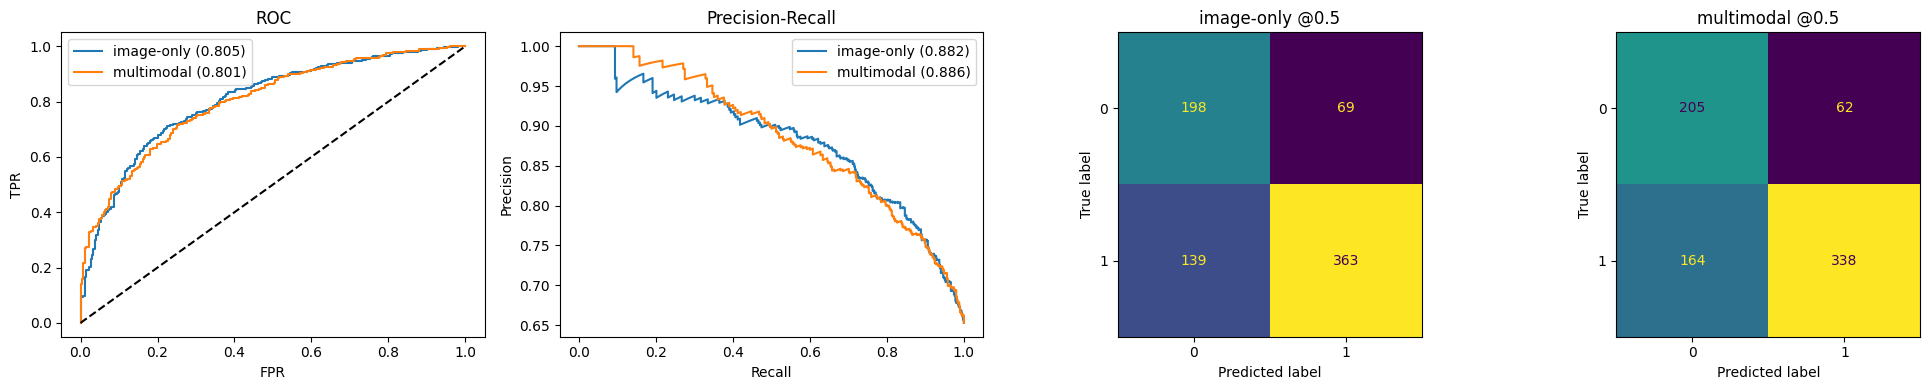

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y"], r["p"]);          ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(r['y'], r['p']):.3f})")
    pr, rc, _   = precision_recall_curve(r["y"], r["p"]); ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(r['y'], r['p']):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC", xlabel="FPR", ylabel="TPR"); ax[0].legend()
ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision"); ax[1].legend()
for a, (name, r) in zip(ax[2:], results.items()):
    ConfusionMatrixDisplay(confusion_matrix(r["y"], r["p"] > 0.5)).plot(ax=a, colorbar=False)
    a.set_title(f"{name} @0.5")
plt.tight_layout(); plt.show()

In [10]:
from sklearn.metrics import f1_score

def best_threshold(model):
    y, p = run_eval(model, val_dl)
    ths = np.linspace(0.05, 0.95, 91)
    return ths[np.argmax([f1_score(y, p > t) for t in ths])]

for name, r in results.items():
    t = best_threshold(r["model"])
    print(f"{name}: val-tuned threshold {t:.2f} -> test F1 {f1_score(r['y'], r['p'] > t):.3f}")

image-only: val-tuned threshold 0.19 -> test F1 0.820
multimodal: val-tuned threshold 0.13 -> test F1 0.820


In [11]:
def eval_shuffled_text(model, seed=0):
    rng = np.random.default_rng(seed)
    d = test_df.copy().reset_index(drop=True)
    d["history"] = rng.permutation(d["history"].values)
    dl = DataLoader(CXRDataset(d, tf_eval), batch_size=32)
    y, p = run_eval(model, dl)
    return roc_auc_score(y, p)

m = results["multimodal"]
orig = roc_auc_score(m["y"], m["p"])
shuf = np.mean([eval_shuffled_text(m["model"], s) for s in range(5)])
print(f"Multimodal AUROC: original text {orig:.3f} | shuffled text {shuf:.3f} | drop {orig - shuf:.3f}")

Multimodal AUROC: original text 0.801 | shuffled text 0.801 | drop -0.000


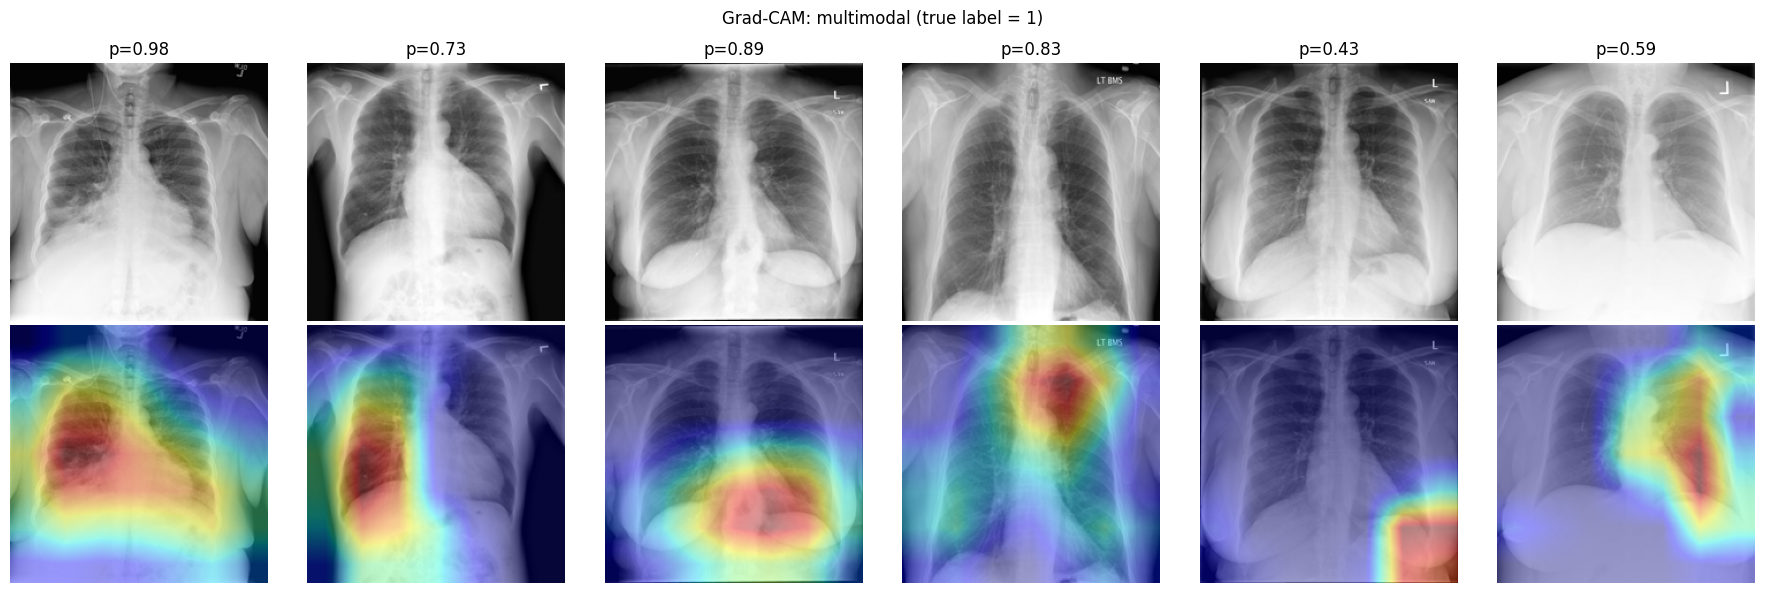

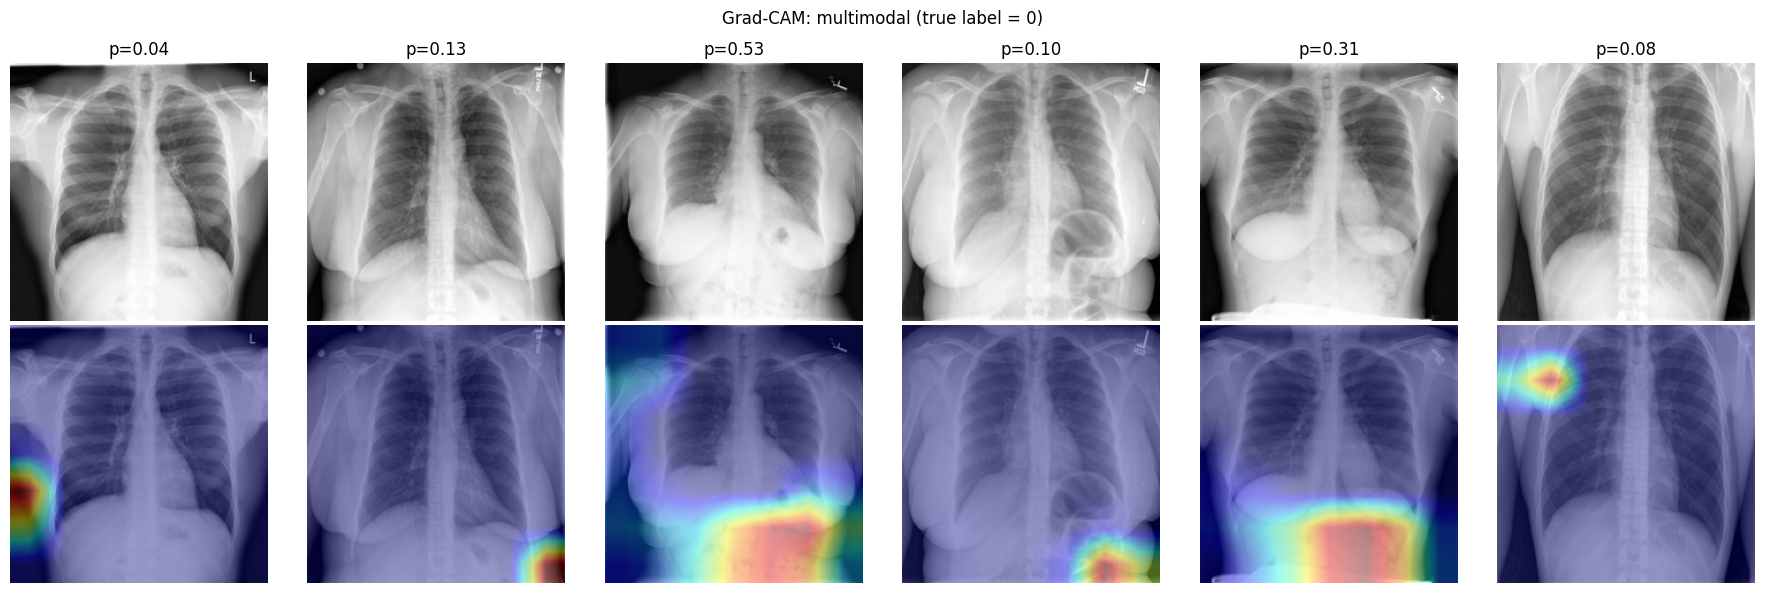

In [12]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model):
        self.model = model.eval()
        layer = model.cnn.layer4[-1]
        layer.register_forward_hook(lambda m, i, o: setattr(self, "act", o))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grad", go[0]))

    def __call__(self, img, ids, mask):
        self.model.zero_grad()
        out = self.model(img, ids, mask); out.sum().backward()
        w = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=img.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze(1)
        cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
        return cam.detach().cpu().numpy(), torch.sigmoid(out).detach().cpu().numpy()

def show_cams(name, n=6, want=1):
    model = results[name]["model"]; cam_fn = GradCAM(model)
    rows = test_df[test_df[LABEL] == want].sample(n, random_state=1)
    ds = CXRDataset(rows, tf_eval)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for i in range(n):
        img, ids, m, y = ds[i]
        cam, prob = cam_fn(img[None].to(dev), ids[None].to(dev), m[None].to(dev))
        raw = Image.open(rows.iloc[i]["path"]).convert("L").resize((224, 224))
        axes[0, i].imshow(raw, cmap="gray"); axes[0, i].set_title(f"p={prob[0]:.2f}"); axes[0, i].axis("off")
        axes[1, i].imshow(raw, cmap="gray"); axes[1, i].imshow(cam[0], cmap="jet", alpha=0.4); axes[1, i].axis("off")
    plt.suptitle(f"Grad-CAM: {name} (true label = {want})"); plt.tight_layout(); plt.show()

show_cams("multimodal", want=1)
show_cams("multimodal", want=0)

## 16. Research interpretation



1. **Task:** binary classification of chest X-ray images into NORMAL and PNEUMONIA.
2. **Method:** ImageNet-pretrained DenseNet121 with a replaced binary classification head.
3. **Data handling:** training augmentation, held-out validation, and untouched test evaluation.
4. **Metrics:** accuracy, precision, sensitivity, specificity, F1, AUROC and AUPRC.
5. **Explainability:** Grad-CAM overlays to inspect spatial evidence used by the model.
6. **Limitations:** dataset provenance and possible duplicate/patient overlap must be checked; folder-level splits do not guarantee patient-level independence; dataset-specific shortcuts and class imbalance may affect performance.
7. **Multimodal extension (Part B):** image + indication text on IU X-Ray, compared against the image-only model on the same split. Only pre-diagnostic text (indication) is used as input; findings/impression/problem tags are used for labelling only, because feeding them in would cause target leakage. Discuss the weak labels, the very small number of pneumonia cases, and the noisy test metrics that result.

